<a href="https://colab.research.google.com/github/Makande340/L03-tree-stability/blob/main/L3_Tree_Stability.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial.
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Mofe Akande, Yafet Gatachew, Eyram Golo

**Date:** 11/18/2026

In [ ]:

# Your Phase 1 solution to the problem goes here.
#Part 1

import pandas as pd
import numpy as np

url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00519/heart_failure_clinical_records_dataset.csv'
df = pd.read_csv(url)

print(df.shape)
print(df.isna().sum().sum())
print(df.duplicated().sum())
df.describe().T

df.columns = df.columns.str.lower()


df['age'] = df['age'].round().astype(int)

df['platelets'] = df['platelets'] / 1000

df['log_cpk'] = np.log(df['creatinine_phosphokinase'])
df['log_creatinine'] = np.log(df['serum_creatinine'])
df = df.drop(columns=['creatinine_phosphokinase', 'serum_creatinine'])

df = df.drop(columns=['time'])

df.head()


(299, 13)
0
0


,age,anaemia,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_sodium,sex,smoking,death_event,log_cpk,log_creatinine
0,75,0,0,20,1,265.00000,130,1,0,1,6.366470,0.641854
1,55,0,0,38,0,263.35803,136,1,0,1,8.969669,0.095310
2,65,0,0,20,0,162.00000,129,1,1,1,4.983607,0.262364
3,50,1,0,20,0,210.00000,137,1,0,1,4.709530,0.641854
4,65,1,1,20,0,327.00000,116,0,0,1,5.075174,0.993252


In [ ]:
#Part 2

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix

SEED = 34

y = df['death_event']
X = df.drop(columns='death_event')

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

tree = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(X_train, y_train)
lm = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_train, y_train)

#Evaluated via test set
for name, model in [('Tree', tree), ('Logistic', lm)]:
    pred = model.predict(X_test)
    print(name, 'accuracy:', round(accuracy_score(y_test, pred), 3))
    print(confusion_matrix(y_test, pred), '\n')

# Predictions set aside
tree_pred_1 = tree.predict(X_test)
lm_pred_1 = lm.predict(X_test)

Tree accuracy: 0.733
[[39  2]
 [14  5]] 

Logistic accuracy: 0.733
[[37  4]
 [12  7]] 



In [ ]:
#Part 3

from sklearn.tree import export_text

seeds = [34, 16, 9, 13, 6]

tree_imps, lm_coefs, accs = {}, {}, []
test_preds = {}   # seed respective test set predictions
full_preds = {}   # full holistic row predictions for seed comparisons

for s in seeds:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=s, stratify=y
    )
    tree = DecisionTreeClassifier(max_depth=3, random_state=s).fit(X_train, y_train)
    lm = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_train, y_train)

    # Each tree printed
    print(f'--- Seed {s} tree ---')
    print(export_text(tree, feature_names=list(X.columns)))

    # Accuracy stated
    accs.append({'seed': s,
                 'tree_acc': accuracy_score(y_test, tree.predict(X_test)),
                 'lm_acc': accuracy_score(y_test, lm.predict(X_test))})

    # Tree importance and LM coefficients
    tree_imps[s] = tree.feature_importances_
    lm_coefs[s] = lm[-1].coef_[0]

    # Predictions set aside
    test_preds[s] = {'tree': tree.predict(X_test), 'lm': lm.predict(X_test)}
    full_preds[f'tree_{s}'] = tree.predict(X)
    full_preds[f'lm_{s}'] = lm.predict(X)

print(pd.DataFrame(accs))
print(pd.DataFrame(tree_imps, index=X.columns).round(2))
print(pd.DataFrame(lm_coefs, index=X.columns).round(2))

full_preds = pd.DataFrame(full_preds)
for s in seeds[1:]:
    tree_diff = (full_preds['tree_34'] != full_preds[f'tree_{s}']).mean()
    lm_diff = (full_preds['lm_34'] != full_preds[f'lm_{s}']).mean()
    print(f'Seed {s}: tree changed {tree_diff:.1%}, LM changed {lm_diff:.1%}')
#Tree were different as Seed 34 tree split first on ejection_fraction while others split on log_creatinine. Cutoffs and low splits changed from seed to seed as well.
#Importance of log_creatinine changed from around .23 and the trees predictions went from 10%-18%

#LM Coefficients - Rather stable for log_creatinine, ejection_fraction and age were seemingly always the largest with similiar signs every time.
#Predictions changed from for onnly 5%-9% of patients

--- Seed 34 tree ---
|--- ejection_fraction <= 22.50
|   |--- log_creatinine <= 0.05
|   |   |--- high_blood_pressure <= 0.50
|   |   |   |--- class: 1
|   |   |--- high_blood_pressure >  0.50
|   |   |   |--- class: 0
|   |--- log_creatinine >  0.05
|   |   |--- class: 1
|--- ejection_fraction >  22.50
|   |--- age <= 79.00
|   |   |--- log_creatinine <= 0.37
|   |   |   |--- class: 0
|   |   |--- log_creatinine >  0.37
|   |   |   |--- class: 0
|   |--- age >  79.00
|   |   |--- log_cpk <= 6.78
|   |   |   |--- class: 1
|   |   |--- log_cpk >  6.78
|   |   |   |--- class: 0

--- Seed 16 tree ---
|--- log_creatinine <= 0.60
|   |--- ejection_fraction <= 32.50
|   |   |--- ejection_fraction <= 22.50
|   |   |   |--- class: 1
|   |   |--- ejection_fraction >  22.50
|   |   |   |--- class: 0
|   |--- ejection_fraction >  32.50
|   |   |--- age <= 79.50
|   |   |   |--- class: 0
|   |   |--- age >  79.50
|   |   |   |--- class: 1
|--- log_creatinine >  0.60
|   |--- log_creatinine <= 0.81

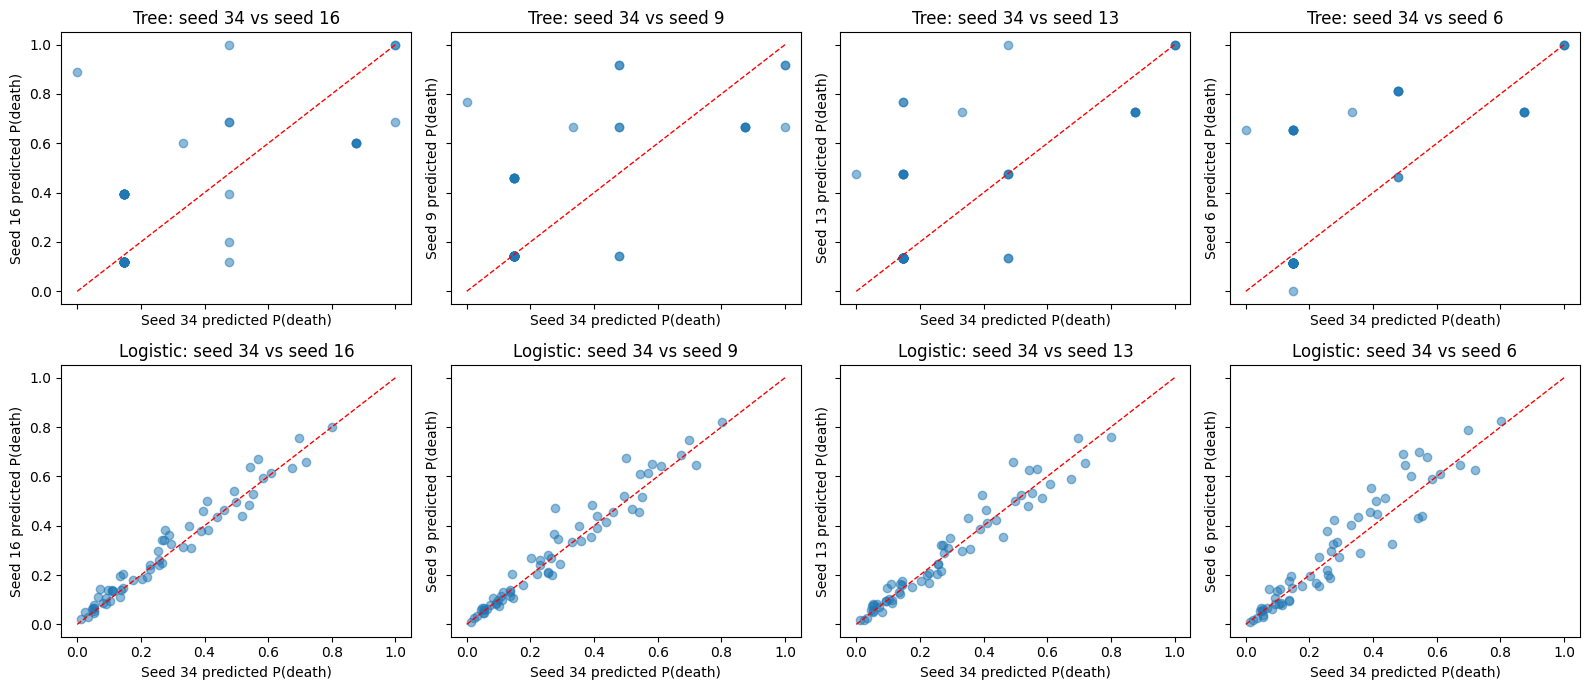

      model  alt_seed  correlation  intercept  slope     R2
0      Tree        16        0.678      0.129  0.666  0.460
1      Tree         9        0.718      0.117  0.711  0.515
2      Tree        13        0.751      0.094  0.805  0.564
3      Tree         6        0.752      0.087  0.889  0.566
4  Logistic        16        0.981      0.023  0.976  0.962
5  Logistic         9        0.974      0.004  1.023  0.949
6  Logistic        13        0.973      0.010  0.975  0.946
7  Logistic         6        0.953      0.001  1.054  0.908
          correlation  intercept  slope     R2
model                                         
Logistic        0.970      0.010  1.007  0.941
Tree            0.725      0.107  0.768  0.526


In [ ]:
#Part 4

import matplotlib.pyplot as plt
from scipy import stats

# Common evaluation set: the seed-34 test set from Part 2
_, X_eval, _, y_eval = train_test_split(
    X, y, test_size=0.2, random_state=34, stratify=y
)

# Re-fit models for every seed and predict PROBABILITIES on the common set
probs = {'tree': {}, 'lm': {}}
for s in seeds:
    X_tr, _, y_tr, _ = train_test_split(
        X, y, test_size=0.2, random_state=s, stratify=y
    )
    t = DecisionTreeClassifier(max_depth=3, random_state=s).fit(X_tr, y_tr)
    l = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_tr, y_tr)
    probs['tree'][s] = t.predict_proba(X_eval)[:, 1]
    probs['lm'][s]   = l.predict_proba(X_eval)[:, 1]

alt_seeds = [s for s in seeds if s != 34]

# 4a. Scatterplots: seed-34 prediction (x) vs alternative seed (y)
fig, axes = plt.subplots(2, len(alt_seeds), figsize=(16, 7), sharex=True, sharey=True)
for row, (name, label) in enumerate([('tree', 'Tree'), ('lm', 'Logistic')]):
    for col, s in enumerate(alt_seeds):
        ax = axes[row, col]
        ax.scatter(probs[name][34], probs[name][s], alpha=0.5)
        ax.plot([0, 1], [0, 1], 'r--', lw=1)   # y = x reference line
        ax.set_title(f'{label}: seed 34 vs seed {s}')
        ax.set_xlabel('Seed 34 predicted P(death)')
        ax.set_ylabel(f'Seed {s} predicted P(death)')
plt.tight_layout()
plt.show()

# 4b + 4c. Correlation and simple linear regression (alt ~ seed 34)
rows = []
for name, label in [('tree', 'Tree'), ('lm', 'Logistic')]:
    for s in alt_seeds:
        res = stats.linregress(probs[name][34], probs[name][s])
        rows.append({
            'model': label, 'alt_seed': s,
            'correlation': res.rvalue,
            'intercept': res.intercept,
            'slope': res.slope,
            'R2': res.rvalue ** 2,
        })
results = pd.DataFrame(rows).round(3)
print(results)
print(results.groupby('model')[['correlation', 'intercept', 'slope', 'R2']].mean().round(3))


###4a Scatterplots
- Logistic: Yes, the predictions look very similar. In all four panels the points sit tightly along the y = x line, with only a little scatter (seed 6 is the loosest).
- Tree: No, they look much less similar. A depth-3 tree gives only a few distinct probabilities, so the points form clusters instead of a cloud, and many sit far from the diagonal (the trees agree mostly at the extremes and disagree in the middle)
###4b Correlations
Logistic models give nearly the same predictions on every split, while trees give noticeably different ones.
- Logistic: highly correlated with the seed-34 model
  - Correlations of 0.953-0.981 (mean 0.970)
- Tree: only moderately correlated
  - Correlations of 0.678-0.752 (mean 0.725)
###4c Regression of alternative predictions on seed-34 predictions
- Logistic: The fits are close to ideal
  - Intercepts are near 0 and slopes are near 1
  - R² is 0.908-0.962, so the seed-34 predictions explain almost all of the variation in the other models' predictions.
- Tree: The fits are much worse
  - Intercepts are well above 0 and slopes are below 1
  - R² is only 0.460-0.566, so the seed-34 tree explains only about half of the variation in another tree's predictions.

- Overall
  - linear models give nearly the same predictions on every split
    - correlation ≈ 0.97
    - intercept ≈ 0
    - slope ≈ 1
    - R² ≈ 0.94

  - And Trees give only moderately consistent predictions
    - correlation ≈ 0.73
    - R² ≈ 0.53

In [ ]:
#Part 5

Across the five splits, the logistic regression models stayed stable in both their coefficients and their predictions. The same three variables (log creatinine, ejection fraction, and age) always had the largest coefficients, their signs never changed, and their values moved only slightly. Their predictions were also nearly identical: correlations with the seed 34 model were 0.95 to 0.98, R squared was about 0.94, the slopes were near 1, the intercepts were near 0, and only 5 to 9 percent of patients changed predicted class. The trees were not stable. Seed 34 split first on ejection fraction while the other seeds split first on log creatinine, and the cutoffs, lower splits, and feature importances all changed between seeds. Their predictions were only moderately consistent, with correlations of 0.68 to 0.75, R squared of about 0.53, and 10 to 18 percent of patients changing predicted class. So on this dataset, linear models give similar coefficients and predictions across train/test splits, but trees do not.

In [ ]:
#Part 6

False. On this dataset, the trees looked substantially different across splits, and their predictions were also noticeably different: a correlation of about 0.73 and an R squared of about 0.53, which is not very similar. The logistic regression predictions were very similar, but those models never looked different to begin with. So no model here both looked very different and still gave very similar predictions.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]